# Research Execution Playbook: Macro-Calibrated Drift Detection

This notebook turns the approved proposal into a reproducible controlled experiment. It compares an unsupervised multivariate autoencoder with River ADWIN on the Statlog German Credit benchmark, then uses SARB and Stats SA series to define transparent synthetic shift scenarios.

## Research questions this notebook addresses
1. **RQ1:** How accurately do the selected unsupervised methods detect known distribution shifts?
2. **RQ2:** How do their detection delays and false-alert behaviour compare?
3. **RQ3:** Do feature-only alerts offer an early signal before retrospective evidence of predictive instability becomes available?

> **Interpretation boundary:** German Credit contains no timestamps. The first 700 ARFF rows form the reference set and the final 300 rows form the operational stream, preserving file order without shuffling. The file has no timestamps, so this is a fixed ordered simulation, not historical chronology. Repetitions vary the autoencoder training seed (weight initialization and minibatch order); they reuse the same records and order. Macro observations calibrate illustrative feature perturbations, not borrower-level records. A separate exploratory replay uses the actual dates of the overlapping macro indicators, but its alerts apply only to those indicators. Results therefore apply to these controlled scenarios, not to real South African applicants or production banks. Injected scenarios change **P(X)** while retaining each record's original label; they do not establish real **P(y|X)** concept drift.

## Reader's guide

This is primarily a **synthetic, non-temporal benchmark**: German Credit has 1,000 records (700 good / 300 bad) and no timestamps. The primary analysis uses the first 700 ARFF rows as reference and the final 300 in file order as the operational stream. One hundred primary repetitions vary autoencoder training randomness only (weight initialization and minibatch order). A separate 100-seed sensitivity analysis permutes the fixed operational records to create artificial pseudo-time orderings; neither source order nor permutation is observed chronology. SARB and CPI values calibrate illustrative feature shifts; they are not joined to borrower records. A separate exploratory analysis replays the overlapping dated macro indicators directly, without assigning dates to credit records.

### Cell-by-cell map

- **0 - Overview:** purpose, research questions, and interpretation boundary.
- **1 - Setup:** run order, repetitions, and local-runtime caveat.
- **2 - Imports/configuration:** libraries, paths, parameters, and output setup.
- **3 - Data rationale:** explains file order and the lack of timestamps.
- **4 - German Credit:** loads ARFF and checks features and class counts.
- **5 - Macro rationale:** identifies aggregate indicators and their role.
- **6 - Macro parsing:** validates SARB series and calculates weighted CPI.
- **7 - Scenario rationale:** defines clean, stress, and macro-calibrated shifts.
- **8 - Scenario metadata:** stores scenario definitions for reporting.
- **9 - Protocol:** explains fixed split, labels, detectors, and metrics.
- **10 - Model/helpers:** fits preprocessing/models, calibrates thresholds, scores alerts, and measures resources.
- **11 - Trial rationale and walkthrough:** explains detector implementations, alarm scoring, and paired evaluation.
- **12 - Primary trial execution:** runs fixed-file-order scenarios and records detector/classifier metrics.
- **13 - Summary rationale:** explains aggregation, conditional tests, and RQ mapping.
- **14 - Results/export:** summarizes primary measurements and saves outputs.
- **15 - Secondary pseudo-time analysis:** tests sensitivity to seeded permutations of the operational records; these are synthetic sequences, not chronology.
- **16 - Dated macro analysis:** monitors the actual monthly macro indicators in date order; reports alert dates, not accuracy or borrower-level findings.
- **17 - Findings and interpretation:** compares analyses and states limits.
- **18 - Extended hypothesis tests:** calibrates input and loss detectors to a shared clean-stream alert budget, measures repeated-event precision/recall on bootstrap streams, and tests a synthetic outcome shift under delayed labels.

### Relationship to Notebook 02

Notebook 02 is the earlier prototype. Notebook 03 keeps file order for its primary 700/300 split, but fits preprocessing on reference training records, calibrates the autoencoder threshold on a held-out reference set, and gives both detectors the same encoded features. It adds a clean control, sensitivity settings, paired post-injection counterfactuals, conditional statistical tests, and resource measurements. The secondary pseudo-time experiment varies only operational-record order.

### Interpreting the paired classifier comparison

A shift alert indicates changed features; it does not prove classifier performance changed. The paired comparison evaluates the same post-onset records unmodified and after injection, with labels unchanged. It therefore measures the effect of these feature perturbations on this classifier and does not establish natural drift in `P(y|X)`. The adaptation exercise uses retrospective labels and should not be presented as deployment validation.

For reporting, distinguish the primary fixed-file-order analysis, the pseudo-time sensitivity, the dated macro-only exploration, and the supplementary hypothesis extensions. Macro timestamps apply to the macro indicators only, not to German Credit borrowers; the macro replay has no labeled drift events and cannot provide detector accuracy. Repetitions vary training seeds or bootstrap/permutation samples from the same dataset; they are not independent datasets. The supplementary label-delay tests use controlled synthetic outcome changes and delays, not a realistic observed credit label-arrival process. State the limits: N=1,000, no borrower timestamps or South African borrower records, synthetic transformations, and local runtime/memory measurement.


## 1. Setup and reproducibility

Run top-to-bottom. The primary analysis uses the proposal's fixed first-700/next-300 split and preserves ARFF file order. It repeats autoencoder training 100 times with different weight initializations and minibatch orders while reusing the same records and sequence; these runs measure training-seed sensitivity, not sampling uncertainty. A separate 100-seed pseudo-time analysis permutes the fixed operational records and is reported only as an ordering sensitivity, not as chronology. The macro-only replay uses actual overlapping monthly dates and reports descriptive alerts only; it does not date credit records. Runtime and sampled process-memory values are local implementation measurements, not production capacity estimates.

In [26]:
from pathlib import Path
import json
import re
import time
import threading
import warnings

import psutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.io import arff
from scipy.stats import binomtest, wilcoxon
from river import drift
from sklearn.compose import ColumnTransformer
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import xgboost as xgb
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
# Repeats vary model initialization only; the record split and order stay fixed.
N_TRIALS = 100
REFERENCE_N = 700
STREAM_N = 300
DRIFT_ONSET = 100
AE_EPOCHS = 20
AE_SIGMAS = (2.0, 3.0, 4.0)
ADWIN_FAMILY_DELTAS = (0.01, 0.05, 0.10)
ALERT_COOLDOWN = 20

# Find the project root without depending on the notebook's launch directory.
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "data" / "micro" / "dataset_31_credit-g.arff").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate data/micro/dataset_31_credit-g.arff from the current directory or its parents.")
MICRO_PATH = ROOT / "data" / "micro" / "dataset_31_credit-g.arff"
SARB_PATH = ROOT / "data" / "macro" / "MonthlyRelease.xlsx"
CPI_CANDIDATES = sorted((ROOT / "data" / "macro").glob("*CPI*202607*.xlsx"))
if not SARB_PATH.is_file():
    raise FileNotFoundError(f"Missing SARB workbook: {SARB_PATH}")
if not CPI_CANDIDATES:
    raise FileNotFoundError(f"Missing Stats SA CPI workbook in {ROOT / 'data' / 'macro'}")
CPI_PATH = CPI_CANDIDATES[0]
OUTPUT_DIR = ROOT / "outputs" / "research_playbook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Project root: {ROOT}\nTrials: {N_TRIALS}; reference/stream: {REFERENCE_N}/{STREAM_N}; output: {OUTPUT_DIR}")

Project root: C:\Users\yntsa\OneDrive\Documents\School\Research Data\AutoEncodesVAdwin
Trials: 100; reference/stream: 700/300; output: C:\Users\yntsa\OneDrive\Documents\School\Research Data\AutoEncodesVAdwin\outputs\research_playbook


## 2. Inspect the German Credit data

The ARFF metadata and class counts are reported before modelling. The analysis preserves the file's row order to match the proposal's fixed 700/300 design, but German Credit has no timestamps: row position is not evidence of chronology. The 700/300 split is therefore an ordered simulation only.

In [27]:
raw, arff_meta = arff.loadarff(MICRO_PATH)
credit = pd.DataFrame(raw)
for col in credit.select_dtypes(include=["object"]).columns:
    credit[col] = credit[col].map(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v)
credit["class"] = credit["class"].astype(str).str.strip()
TARGET = "class"
NUMERIC = credit.drop(columns=TARGET).select_dtypes(include=[np.number]).columns.tolist()
CATEGORICAL = [c for c in credit.columns if c not in NUMERIC + [TARGET]]
assert len(credit) == 1000, f"Expected 1,000 rows, found {len(credit)}"
assert credit[TARGET].isin(["good", "bad"]).all(), "Unexpected target labels"
assert credit[NUMERIC + CATEGORICAL].notna().all().all(), "Unexpected missing predictor values"
print("Rows/columns:", credit.shape)
print("Numeric / categorical predictors:", len(NUMERIC), "/", len(CATEGORICAL))
print("Target counts:", credit[TARGET].value_counts().to_dict())
print("Numeric predictors:", NUMERIC)
print("Categorical predictors:", CATEGORICAL)
print("Dataset metadata name:", getattr(arff_meta, "name", "unavailable"))

Rows/columns: (1000, 21)
Numeric / categorical predictors: 7 / 13
Target counts: {'good': 700, 'bad': 300}
Numeric predictors: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical predictors: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
Dataset metadata name: german_credit


## 3. Read and validate macroeconomic series

**SARB:** use the published year-over-year percentage for *Total loans and advances*, not a repo-rate series (this workbook does not provide the repo rate). **Stats SA:** calculate a transparent item-weighted index from monthly CPI item indices, then calculate the latest 12-month percentage change. These are aggregate indicators; applying their rates to loan features below is an explicit simulation assumption, not an estimated causal relationship.

In [28]:
# The SARB workbook has grouped headings in row 1 and variable headings in row 2.
sarb_raw = pd.read_excel(SARB_PATH, sheet_name="Monthly Release", header=None)
if len(sarb_raw) < 3:
    raise ValueError("SARB workbook does not have the expected two header rows and data rows.")
group_row = sarb_raw.iloc[0].fillna("").astype(str).str.strip()
variable_row = sarb_raw.iloc[1].fillna("").astype(str).str.strip()
sarb_matches = [i for i, value in enumerate(variable_row) if value == "Total loans and advances"]
if len(sarb_matches) != 1:
    raise ValueError(f"Expected one SARB 'Total loans and advances' column, found {len(sarb_matches)}.")
sarb_col = sarb_matches[0]
# Excel's merged group heading is stored only in its first cell.
preceding_groups = [str(group_row.iloc[i]).strip() for i in range(sarb_col + 1)
                    if str(group_row.iloc[i]).strip() and str(group_row.iloc[i]).strip() != "nan"]
if not preceding_groups or preceding_groups[-1] != "Percentage change over 12 months":
    raise ValueError(f"Unexpected SARB grouped heading for loans growth: {preceding_groups[-1:]}")
sarb = pd.DataFrame({
    "date": pd.to_datetime(sarb_raw.iloc[2:, 0].astype(str).str.strip(), format="%b, %Y", errors="coerce"),
    "loans_advances_yoy_pct": pd.to_numeric(
        sarb_raw.iloc[2:, sarb_col].astype(str).str.replace(" ", "", regex=False), errors="coerce"
    ),
}).dropna().sort_values("date").reset_index(drop=True)
if len(sarb) < 13:
    raise ValueError("Fewer than 13 valid SARB monthly growth observations; cannot calculate current YoY context.")

# Stats SA workbook contains item weights and monthly columns named MYYYYMM.
cpi_raw = pd.read_excel(CPI_PATH, sheet_name=0)
month_cols = sorted(c for c in cpi_raw.columns if isinstance(c, str) and re.fullmatch(r"M20\d{4}", c))
if len(month_cols) < 13 or "Weight" not in cpi_raw:
    raise ValueError("CPI workbook is missing the expected monthly MYYYYMM columns or Weight column.")
weights = pd.to_numeric(cpi_raw["Weight"], errors="coerce")
cpi_values = cpi_raw[month_cols].apply(pd.to_numeric, errors="coerce")
weighted_numerator = cpi_values.mul(weights, axis=0).sum(axis=0, min_count=1)
valid_weight = cpi_values.notna().mul(weights, axis=0).sum(axis=0)
cpi_index = weighted_numerator / valid_weight
if cpi_index.iloc[-13] <= 0:
    raise ValueError("CPI index 12 months before the latest month is not positive.")
cpi_yoy_pct = float((cpi_index.iloc[-1] / cpi_index.iloc[-13] - 1.0) * 100.0)
latest_sarb = float(sarb["loans_advances_yoy_pct"].iloc[-1])
latest_sarb_date = sarb["date"].iloc[-1].strftime("%Y-%m")
latest_cpi_month = month_cols[-1]
latest_cpi_date = f"{latest_cpi_month[1:5]}-{latest_cpi_month[5:7]}"
macro_summary = pd.DataFrame([
    {"series": "SARB total loans and advances, YoY", "latest_month": latest_sarb_date,
     "latest_value_pct": latest_sarb, "construction": "Published YoY column in Monthly Release"},
    {"series": "Stats SA CPI, item-weighted index YoY", "latest_month": latest_cpi_date,
      "latest_value_pct": cpi_yoy_pct, "construction": "Sum(item index multiplied by item weight) / sum(valid item weights); latest / 12-month-prior - 1"},
])
print("SARB coverage:", sarb.date.min().date(), "to", sarb.date.max().date(), "valid months:", len(sarb))
print("CPI coverage:", month_cols[0], "to", month_cols[-1], "months:", len(month_cols),
      "latest valid item rows:", int(cpi_values.iloc[:, -1].notna().sum()),
      "item-weight total:", round(float(weights.sum()), 4))
display(macro_summary)
macro_summary.to_csv(OUTPUT_DIR / "macro_calibration.csv", index=False)

SARB coverage: 1966-03-01 to 2026-07-01 valid months: 725
CPI coverage: M200801 to M202607 months: 223 latest valid item rows: 391 item-weight total: 100.0


,series,latest_month,latest_value_pct,construction
0,"SARB total loans and advances, YoY",2026-07,7.340000,Published YoY column in Monthly Release
1,"Stats SA CPI, item-weighted index YoY",2026-07,4.282273,Sum(item index multiplied by item weight) / su...


## 4. Define controlled, separate scenarios

The proposal's 40% sudden, 0-to-35% gradual, and 25% recurring amplitudes are retained as planned stress scenarios. Two additional scenarios use the latest observed SARB lending-growth and CPI inflation rates as simple illustrative multipliers on `credit_amount`. The feature transforms are applied on **raw** values before train-fitted scaling. Labels are carried unchanged for retrospective evaluation only.

The recurring period below is 12 **synthetic observations**, not 12 real months: the benchmark has no dates. These controlled perturbations establish known P(X) shift onset, not real macroeconomic causation.

In [29]:
SCENARIOS = ["clean", "sudden_40pct", "gradual_0_to_35pct", "recurring_25pct",
             "sarb_observed_yoy", "cpi_observed_yoy"]
SCENARIO_NOTES = {
    "clean": "No feature perturbation; control for false alerts.",
    "sudden_40pct": "At onset, multiply raw credit_amount and duration by 1.40 (proposal stress magnitude).",
    "gradual_0_to_35pct": "From onset to stream end, ramp both raw features linearly from 1.00 to 1.35.",
    "recurring_25pct": "From onset, multiply both features by 1 + 0.25*sin(2*pi*k/12); synthetic period only.",
    "sarb_observed_yoy": "At onset, multiply raw credit_amount by 1 + latest SARB total-loans-and-advances YoY/100.",
    "cpi_observed_yoy": "From onset to stream end, ramp raw credit_amount from 1.00 to 1 + latest weighted CPI YoY/100.",
}
scenario_table = pd.DataFrame([{"scenario": name, "drift_onset": None if name == "clean" else DRIFT_ONSET,
                                "macro_anchor": "SARB" if name == "sarb_observed_yoy" else "Stats SA CPI" if name == "cpi_observed_yoy" else "Proposal parameter/control",
                                "definition": SCENARIO_NOTES[name]} for name in SCENARIOS])
display(scenario_table)
scenario_table.to_csv(OUTPUT_DIR / "scenario_definitions.csv", index=False)

def make_scenario(raw_stream, scenario):
    """Return a copied raw predictor frame after one documented synthetic perturbation."""
    changed = raw_stream.copy().reset_index(drop=True)
    n = len(changed)
    position = np.arange(n)
    after = position >= DRIFT_ONSET
    if scenario == "clean":
        return changed
    if scenario == "sudden_40pct":
        factor = np.where(after, 1.40, 1.0)
        for col in ("credit_amount", "duration"):
            changed[col] = changed[col].to_numpy() * factor
    elif scenario == "gradual_0_to_35pct":
        progress = np.clip((position - DRIFT_ONSET) / max(n - DRIFT_ONSET - 1, 1), 0.0, 1.0)
        factor = 1.0 + 0.35 * progress
        for col in ("credit_amount", "duration"):
            changed[col] = changed[col].to_numpy() * factor
    elif scenario == "recurring_25pct":
        phase = np.maximum(position - DRIFT_ONSET, 0)
        factor = np.where(after, 1.0 + 0.25 * np.sin(2.0 * np.pi * phase / 12.0), 1.0)
        for col in ("credit_amount", "duration"):
            changed[col] = changed[col].to_numpy() * factor
    elif scenario == "sarb_observed_yoy":
        changed.loc[after, "credit_amount"] *= 1.0 + latest_sarb / 100.0
    elif scenario == "cpi_observed_yoy":
        progress = np.clip((position - DRIFT_ONSET) / max(n - DRIFT_ONSET - 1, 1), 0.0, 1.0)
        changed["credit_amount"] *= 1.0 + (cpi_yoy_pct / 100.0) * progress
    else:
        raise ValueError(f"Unknown scenario: {scenario}")
    return changed

,scenario,drift_onset,macro_anchor,definition
0,clean,NaN,Proposal parameter/control,No feature perturbation; control for false ale...
1,sudden_40pct,100.0,Proposal parameter/control,"At onset, multiply raw credit_amount and durat..."
2,gradual_0_to_35pct,100.0,Proposal parameter/control,"From onset to stream end, ramp both raw featur..."
3,recurring_25pct,100.0,Proposal parameter/control,"From onset, multiply both features by 1 + 0.25..."
4,sarb_observed_yoy,100.0,SARB,"At onset, multiply raw credit_amount by 1 + la..."
5,cpi_observed_yoy,100.0,Stats SA CPI,"From onset to stream end, ramp raw credit_amou..."


## 5. Detector and evaluation protocol

Each run uses the first 700 ARFF rows as reference and the final 300 as operational stream, preserving their file order. The first 560 reference rows fit preprocessing, the classifier, and autoencoder; the remaining 140 calibrate the autoencoder threshold and assess baseline performance. Labels are not supplied to either detector. One River ADWIN instance monitors each encoded feature with a Bonferroni-adjusted delta; an alert by any feature is a detector alert. Point alarms are merged with a 20-observation refractory interval. The 100 repetitions vary autoencoder initialization seeds only; ADWIN and the row sequence are deterministic and unchanged.

For each synthetic drift event, **event recall** indicates whether any alert occurs at or after onset; **delay** is the first such alert minus onset; and **false-alert rate** is pre-onset false-alert episodes divided by stable observations. Event-level **false-discovery rate (FDR)** is false alert episodes divided by all counted false-alert episodes plus the one detected event; it is undefined when no alert occurs. In the clean control, every alert is false. Statistical comparisons are conditional on this fixed dataset and row order and quantify variation across autoencoder initializations; they do not establish general detector performance across independent datasets or real banking populations.

### How the two detection methods compare

The autoencoder and ADWIN look for changes in different ways, so they are complementary detectors rather than interchangeable algorithms:

| Aspect | Autoencoder | ADWIN |
|---|---|---|
| **What it monitors** | Reconstruction error for each complete encoded record, using all features together. | Each encoded feature as its own one-dimensional stream. |
| **How an alert is raised** | A record is flagged when its reconstruction error exceeds a threshold calibrated on the 140 reference-only calibration records (mean error plus 2, 3, or 4 standard deviations). | River's adaptive window signals a distribution change in a feature; an alert is recorded if any feature signals. Its delta is divided by the number of encoded features to target a family-wise delta of 0.01, 0.05, or 0.10. |
| **What it can capture** | Unusual combinations or relationships among features, provided they produce a large reconstruction error. | Changes in individual feature streams; it does not directly model cross-feature relationships. |
| **Main trade-off** | Learns a reference pattern and can use multivariate structure, but requires model fitting and a calibrated threshold; results depend on the learned representation and threshold. | Adapts its window to the stream and does not require a trained neural model, but monitoring features separately may miss changes visible only in feature relationships. |

For a fair empirical comparison, both detectors receive the same preprocessed features and seeded stream, with no labels. Their point alarms are reduced to alert episodes using the same 20-observation refractory interval, then scored against the same known synthetic onset using event recall, detection delay (in observations), and pre-onset false-alert rate. The clean scenario measures false alerts when no shift was injected. These shared metrics make outcomes comparable, but do not make the algorithms' internal thresholds equivalent: report the primary 3-sigma autoencoder and 0.05 family-wise ADWIN settings, and use the sensitivity settings to show how conclusions depend on threshold choice. Runtime measurements cover stream detection; autoencoder training time is recorded separately, so include it when discussing total computational cost.

Neither method identifies the cause of an alert or establishes that predictive performance has declined. This experiment tests detection of the specified synthetic feature shifts in a small, non-temporal benchmark; it cannot establish that either method is universally better or ready for production.

In [30]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, input_dim)
        )

    def forward(self, x):
        return self.network(x)

def reconstruction_errors(model, matrix):
    model.eval()
    with torch.no_grad():
        tensor = torch.as_tensor(matrix, dtype=torch.float32)
        return ((model(tensor) - tensor) ** 2).mean(dim=1).cpu().numpy()

def alert_episodes(indices, cooldown=ALERT_COOLDOWN):
    episodes = []
    for idx in sorted(set(int(i) for i in indices)):
        if not episodes or idx - episodes[-1] > cooldown:
            episodes.append(idx)
    return episodes

def score_alerts(alert_indices, onset, n_stream):
    alerts = alert_episodes(alert_indices)
    if onset is None:
        false_alerts = len(alerts)
        return {"event_recall": np.nan, "delay": np.nan, "false_alert_events": false_alerts,
                "false_alert_rate": false_alerts / n_stream,
                "event_precision": 0.0 if false_alerts else np.nan,
                "false_discovery_rate": 1.0 if false_alerts else np.nan, "missed": np.nan}
    pre = [a for a in alerts if a < onset]
    post = [a for a in alerts if a >= onset]
    detected = bool(post)
    tp, fp = int(detected), len(pre)
    alert_count = tp + fp
    return {"event_recall": float(detected), "delay": float(post[0] - onset) if detected else np.nan,
            "false_alert_events": fp, "false_alert_rate": fp / max(onset, 1),
            "event_precision": tp / alert_count if alert_count else np.nan,
            "false_discovery_rate": fp / alert_count if alert_count else np.nan,
            "missed": int(not detected)}

def classifier_scores(model, matrix, labels):
    probabilities = model.predict_proba(matrix)[:, 1]
    auc = roc_auc_score(labels, probabilities) if len(np.unique(labels)) == 2 else np.nan
    return float(auc), float(log_loss(labels, probabilities, labels=[0, 1]))

def measure_peak_process_rss(operation, sample_seconds=0.25):
    process = psutil.Process()
    baseline_rss = process.memory_info().rss
    peak_rss = [baseline_rss]
    stop_sampling = threading.Event()

    def sample_rss():
        while not stop_sampling.wait(0.001):
            peak_rss[0] = max(peak_rss[0], process.memory_info().rss)

    sampler = threading.Thread(target=sample_rss, daemon=True)
    sampler.start()
    repetitions = 0
    started = time.perf_counter()
    try:
        while time.perf_counter() - started < sample_seconds:
            operation()
            repetitions += 1
    finally:
        stop_sampling.set()
        sampler.join()
    peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
    return baseline_rss, peak_rss[0], repetitions

# Fail early if the chosen feature columns aren't present.
assert {"credit_amount", "duration"}.issubset(credit.columns)
print(f"Reference training/calibration: {REFERENCE_N - 140}/140; synthetic stream: {STREAM_N}; onset: {DRIFT_ONSET}")
print("ADWIN delta values are family-wise targets divided by encoded feature count; AE thresholds use calibration-only errors.")

Reference training/calibration: 560/140; synthetic stream: 300; onset: 100
ADWIN delta values are family-wise targets divided by encoded feature count; AE thresholds use calibration-only errors.


## 6. Repeated comparative experiment

The primary comparison uses the autoencoder's 3-sigma threshold and ADWIN family-wise delta 0.05. Sensitivity tables retain the 2/3/4-sigma and 0.01/0.05/0.10 settings. All runs use the same first-700/next-300 records in original file order; only the autoencoder initialization seed changes. Classifier AUC/log-loss is evaluated retrospectively by comparing the pre-onset segment and the paired post-onset records with and without injection. Labels are never detector inputs. A secondary retraining check fits on the first two-thirds of post-onset records and evaluates on the final third; it is simulated adaptation using retrospective labels, not proof of deployment recovery.

### What happens in each experiment trial

Each of the 100 repetitions uses the same first 700 reference rows and final 300 operational rows in original ARFF file order. No record or stream order is shuffled. The seed varies autoencoder initialization; the XGBoost classifier uses a fixed seed and ADWIN is deterministic. Since the dataset has no dates, stream position is only a controlled simulation index; position 100 is the injected onset, not a calendar date. These repetitions characterize initialization sensitivity, not uncertainty across independent datasets or credit portfolios.

1. **Create a reference baseline.** The first 560 reference records fit the numeric/categorical preprocessing, the classifier used for retrospective performance checks, and the autoencoder. The other 140 reference records are held out: they calibrate the autoencoder threshold and provide a baseline score. The detector inputs contain features only; class labels are not passed to either detector.
2. **Train and calibrate the autoencoder.** The network learns to reconstruct encoded reference records. For each stream record it calculates the mean squared reconstruction error across encoded features. A high error means the record does not fit the learned reference representation well. The experiment tests thresholds at the calibration-set mean error plus 2, 3, or 4 standard deviations; the primary setting is 3 standard deviations. Lower thresholds can catch more unusual records, but can also flag more ordinary variation.
3. **Set up ADWIN on the same representation.** There is one River ADWIN instance for each encoded feature. As each stream row arrives, every instance receives that feature's value and maintains an adaptive window to test for a change in its stream. The row is flagged if any feature's detector signals drift. To account for checking many features, each detector receives the chosen family-wise delta divided by the encoded feature count; the primary family-wise delta is 0.05.
4. **Replay controlled scenarios.** Both detectors see the same transformed 300-row stream in each scenario: an unchanged clean control, a simultaneous 40% increase in credit amount and duration, gradual and recurring changes to those features, and two credit-amount changes anchored to the selected SARB lending-growth and CPI observations. These are artificial feature shifts, not borrower histories or causal macroeconomic effects.
5. **Score alarms consistently.** Adjacent or nearby point alarms are consolidated with the shared 20-observation refractory interval. For each injected shift, event recall is the fraction of autoencoder initializations with at least one alert at or after onset; ADWIN produces the same result on each repeated fixed stream. Delay is the first such alert's position minus 100. Pre-onset false-alert rate counts alert episodes before the known shift, while event-level FDR is reported separately. In the clean control, every alert is false. Delay is measured in observations, not elapsed time.
6. **Check predictive impact separately.** After detection scoring, the trained classifier is evaluated with labels for retrospective analysis only. The paired post-onset comparison uses the exact same records and labels once unmodified and once shifted, so it isolates the artificial feature transformation from random sample composition. This assesses whether these particular shifts changed this classifier's scores; it is not an input to either detector.

The two detectors therefore share the data, preprocessing, stream order, onset, alarm grouping, and evaluation metrics, but they do not share a decision rule. The autoencoder asks whether a complete record reconstructs poorly under a learned multivariate reference model; ADWIN asks whether a monitored feature stream has changed over its adaptive window. Differences in their results should be interpreted as performance under these specific model, threshold, stream-size, and shift choices.

In [31]:
trial_rows = []
recovery_rows = []

def fit_ae(train_matrix, seed):
    torch.manual_seed(seed)
    model = Autoencoder(train_matrix.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    loader = DataLoader(TensorDataset(torch.as_tensor(train_matrix, dtype=torch.float32)),
                        batch_size=64, shuffle=True)
    model.train()
    for _ in range(AE_EPOCHS):
        for (batch,) in loader:
            optimizer.zero_grad()
            loss = ((model(batch) - batch) ** 2).mean()
            loss.backward()
            optimizer.step()
    return model

for trial in range(N_TRIALS):
    seed = SEED + trial
    ref_idx = np.arange(REFERENCE_N)
    stream_idx = np.arange(REFERENCE_N, REFERENCE_N + STREAM_N)
    train_idx, calibration_idx = ref_idx[:560], ref_idx[560:]
    raw_train = credit.iloc[train_idx].drop(columns=TARGET).copy()
    raw_cal = credit.iloc[calibration_idx].drop(columns=TARGET).copy()
    raw_stream = credit.iloc[stream_idx].drop(columns=TARGET).copy().reset_index(drop=True)
    y_train = (credit.iloc[train_idx][TARGET].to_numpy() == "good").astype(int)
    y_cal = (credit.iloc[calibration_idx][TARGET].to_numpy() == "good").astype(int)
    y_stream = (credit.iloc[stream_idx][TARGET].to_numpy() == "good").astype(int)

    transformer = ColumnTransformer([
        ("numeric", RobustScaler(), NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ], remainder="drop")
    x_train = np.asarray(transformer.fit_transform(raw_train), dtype=np.float32)
    x_cal = np.asarray(transformer.transform(raw_cal), dtype=np.float32)
    x_stream_unmodified = np.asarray(transformer.transform(raw_stream), dtype=np.float32)

    classifier = xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05,
                                   random_state=SEED, eval_metric="logloss", n_jobs=1)
    classifier.fit(x_train, y_train)
    base_auc, base_loss = classifier_scores(classifier, x_cal, y_cal)

    ae_start = time.perf_counter()
    ae = fit_ae(x_train, seed)
    ae_train_seconds = time.perf_counter() - ae_start
    cal_errors = reconstruction_errors(ae, x_cal)
    cal_mean, cal_std = float(cal_errors.mean()), float(cal_errors.std(ddof=0))
    thresholds = {sigma: cal_mean + sigma * cal_std for sigma in AE_SIGMAS}

    for scenario in SCENARIOS:
        raw_test = make_scenario(raw_stream, scenario)
        x_test = np.asarray(transformer.transform(raw_test), dtype=np.float32)
        auc, loss = classifier_scores(classifier, x_test, y_stream)
        onset = None if scenario == "clean" else DRIFT_ONSET
        # Retrospective paired evaluation: same people and labels, before onset
        # and after injection versus the same post-onset records unmodified.
        pre_auc, pre_loss = classifier_scores(classifier, x_test[:DRIFT_ONSET], y_stream[:DRIFT_ONSET])
        post_clean_auc, post_clean_loss = classifier_scores(
            classifier, x_stream_unmodified[DRIFT_ONSET:], y_stream[DRIFT_ONSET:])
        post_injected_auc, post_injected_loss = classifier_scores(
            classifier, x_test[DRIFT_ONSET:], y_stream[DRIFT_ONSET:])
        post_auc_delta = post_injected_auc - post_clean_auc
        post_loss_delta = post_injected_loss - post_clean_loss
        start = time.perf_counter()
        errors = reconstruction_errors(ae, x_test)
        ae_seconds = time.perf_counter() - start
        for sigma, threshold in thresholds.items():
            hits = np.flatnonzero(errors > threshold)
            result = score_alerts(hits, onset, len(x_test))
            trial_rows.append({"trial": trial, "seed": seed, "scenario": scenario,
                "detector": "Autoencoder", "setting": f"{sigma:g}-sigma", **result,
                "auc_reference_calibration": base_auc, "logloss_reference_calibration": base_loss,
                "auc_operational": auc, "logloss_operational": loss,
                "auc_pre_onset": pre_auc, "logloss_pre_onset": pre_loss,
                "auc_post_unmodified_counterfactual": post_clean_auc,
                "logloss_post_unmodified_counterfactual": post_clean_loss,
                "auc_post_injected": post_injected_auc, "logloss_post_injected": post_injected_loss,
                "auc_post_injection_delta_vs_same_records": post_auc_delta,
                "logloss_post_injection_delta_vs_same_records": post_loss_delta,
                "auc_change_vs_reference": auc - base_auc, "runtime_seconds": ae_seconds,
                "ae_training_seconds": ae_train_seconds, "n_features": x_test.shape[1]})

        for family_delta in ADWIN_FAMILY_DELTAS:
            detectors = [drift.ADWIN(delta=family_delta / x_test.shape[1]) for _ in range(x_test.shape[1])]
            hits = []
            start = time.perf_counter()
            for row_idx, row in enumerate(x_test):
                flagged = False
                for detector, value in zip(detectors, row):
                    detector.update(float(value))
                    flagged = flagged or detector.drift_detected
                if flagged:
                    hits.append(row_idx)
            adwin_seconds = time.perf_counter() - start
            result = score_alerts(hits, onset, len(x_test))
            trial_rows.append({"trial": trial, "seed": seed, "scenario": scenario,
                "detector": "ADWIN", "setting": f"family-delta-{family_delta:g}", **result,
                "auc_reference_calibration": base_auc, "logloss_reference_calibration": base_loss,
                "auc_operational": auc, "logloss_operational": loss,
                "auc_pre_onset": pre_auc, "logloss_pre_onset": pre_loss,
                "auc_post_unmodified_counterfactual": post_clean_auc,
                "logloss_post_unmodified_counterfactual": post_clean_loss,
                "auc_post_injected": post_injected_auc, "logloss_post_injected": post_injected_loss,
                "auc_post_injection_delta_vs_same_records": post_auc_delta,
                "logloss_post_injection_delta_vs_same_records": post_loss_delta,
                "auc_change_vs_reference": auc - base_auc, "runtime_seconds": adwin_seconds,
                "ae_training_seconds": np.nan, "n_features": x_test.shape[1]})

        if onset is not None and trial == 0:
            adapt_end = onset + int((len(x_test) - onset) * 2 / 3)
            if adapt_end > onset and len(x_test) - adapt_end >= 2:
                adapted = xgb.XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05,
                    random_state=SEED, eval_metric="logloss", n_jobs=1)
                adapted.fit(x_test[onset:adapt_end], y_stream[onset:adapt_end])
                adapted_auc, adapted_loss = classifier_scores(adapted, x_test[adapt_end:], y_stream[adapt_end:])
                baseline_auc, baseline_loss = classifier_scores(classifier, x_test[adapt_end:], y_stream[adapt_end:])
                recovery_rows.append({"trial": trial, "seed": seed, "scenario": scenario,
                    "evaluation_n": len(x_test) - adapt_end, "baseline_auc": baseline_auc,
                    "adapted_auc": adapted_auc, "auc_change": adapted_auc - baseline_auc,
                    "baseline_logloss": baseline_loss, "adapted_logloss": adapted_loss,
                    "label_use": "post-onset labels used for simulated adaptation; final third held out"})

    if (trial + 1) % max(1, N_TRIALS // 5) == 0:
        print(f"Completed trial {trial + 1}/{N_TRIALS}")

trial_results = pd.DataFrame(trial_rows)
recovery_results = pd.DataFrame(recovery_rows)

# Estimate peak process RSS during repeated scoring on the final fixed stream/scenario.
def run_adwin_memory_sample():
    detectors = [drift.ADWIN(delta=0.05 / x_test.shape[1]) for _ in range(x_test.shape[1])]
    for row in x_test:
        for detector, value in zip(detectors, row):
            detector.update(float(value))

memory_rows = []
for detector_name, operation in [
    ("Autoencoder", lambda: reconstruction_errors(ae, x_test)),
    ("ADWIN", run_adwin_memory_sample),
]:
    baseline_rss, peak_rss, repetitions = measure_peak_process_rss(operation)
    memory_rows.append({
        "detector": detector_name,
        "sample_scenario": SCENARIOS[-1],
        "repetitions_sampled": repetitions,
        "baseline_process_rss_mb": baseline_rss / (1024 ** 2),
        "peak_process_rss_mb": peak_rss / (1024 ** 2),
        "incremental_peak_process_rss_mb": max(0, peak_rss - baseline_rss) / (1024 ** 2),
        "measurement": "sampled process RSS; includes interpreter, data, and fitted models",
    })
resource_summary = pd.DataFrame(memory_rows)
resource_summary.to_csv(OUTPUT_DIR / "resource_summary.csv", index=False)
trial_results.to_csv(OUTPUT_DIR / "trial_metrics.csv", index=False)
recovery_results.to_csv(OUTPUT_DIR / "adaptation_holdout_metrics.csv", index=False)
print("Rows:", len(trial_results), "detector/scenario/setting/initialization measurements")
print("Sampled process RSS during repeated detector scoring:")
display(resource_summary.round(4))

Completed trial 20/100
Completed trial 40/100
Completed trial 60/100
Completed trial 80/100
Completed trial 100/100
Rows: 3600 detector/scenario/setting/initialization measurements
Sampled process RSS during repeated detector scoring:


,detector,sample_scenario,repetitions_sampled,baseline_process_rss_mb,peak_process_rss_mb,incremental_peak_process_rss_mb,measurement
0,Autoencoder,cpi_observed_yoy,683,378.2539,378.4062,0.1523,"sampled process RSS; includes interpreter, dat..."
1,ADWIN,cpi_observed_yoy,50,378.4023,378.4219,0.0195,"sampled process RSS; includes interpreter, dat..."


## 7. Summarize results and answer the research questions

Report the primary 3-sigma autoencoder and 0.05 family-wise ADWIN results first. Sensitivity settings remain available for context. Means/standard deviations summarize repeated autoencoder initializations on the same fixed records and row order; they are not uncertainty estimates over a South African banking population. The hypothesis-test table is conditional on this fixed benchmark and tests seed-to-seed initialization variability only.

,scenario,detector,trials,event_recall_mean,event_recall_sd,delay_mean,delay_sd,false_alert_rate_mean,event_precision_mean,false_discovery_rate_mean,auc_operational_mean,auc_change_mean,runtime_seconds_mean
0,clean,ADWIN,100,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,0.7724,0.0709,0.0093
1,clean,Autoencoder,100,NaN,NaN,NaN,NaN,0.0104,0.0000,1.0000,0.7724,0.0709,0.0008
2,cpi_observed_yoy,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN,0.7735,0.0721,0.0091
3,cpi_observed_yoy,Autoencoder,100,0.99,0.1000,20.9798,16.9429,0.0065,0.7000,0.3000,0.7735,0.0721,0.0007
4,gradual_0_to_35pct,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN,0.7782,0.0768,0.0091
5,gradual_0_to_35pct,Autoencoder,100,1.00,0.0000,21.8800,19.1038,0.0065,0.7050,0.2950,0.7782,0.0768,0.0008
6,recurring_25pct,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN,0.7767,0.0752,0.0091
7,recurring_25pct,Autoencoder,100,0.97,0.1714,19.7320,12.1445,0.0065,0.6919,0.3081,0.7767,0.0752,0.0008
8,sarb_observed_yoy,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN,0.7785,0.0771,0.0092
9,sarb_observed_yoy,Autoencoder,100,0.99,0.1000,19.0000,9.9499,0.0065,0.7000,0.3000,0.7785,0.0771,0.0007


,scenario,detector,setting,trials,event_recall_mean,delay_mean,false_alert_rate_mean,event_precision_mean
0,clean,ADWIN,family-delta-0.01,100,NaN,NaN,0.0000,NaN
1,clean,ADWIN,family-delta-0.05,100,NaN,NaN,0.0000,NaN
2,clean,ADWIN,family-delta-0.1,100,NaN,NaN,0.0000,NaN
3,clean,Autoencoder,2-sigma,100,NaN,NaN,0.0260,0.0000
4,clean,Autoencoder,3-sigma,100,NaN,NaN,0.0104,0.0000
5,clean,Autoencoder,4-sigma,100,NaN,NaN,0.0029,0.0000
6,cpi_observed_yoy,ADWIN,family-delta-0.01,100,0.00,NaN,0.0000,NaN
7,cpi_observed_yoy,ADWIN,family-delta-0.05,100,0.00,NaN,0.0000,NaN
8,cpi_observed_yoy,ADWIN,family-delta-0.1,100,0.00,NaN,0.0000,NaN
9,cpi_observed_yoy,Autoencoder,2-sigma,100,1.00,15.4900,0.0257,0.2875


Conditional paired tests (interpret only as initialization sensitivity on this fixed stream):


,scenario,metric,test,n_comparable_initializations,autoencoder_only_wins,adwin_only_wins,p_value_raw,p_value_holm_within_metric,scope
0,clean,event_recall,exact paired binomial (discordant initializati...,100,0.0,0.0,1.0,1.0,fixed records/order; repeated AE initializatio...
1,clean,delay,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
2,clean,event_precision,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
3,clean,event_fdr,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
4,clean,false_alert_episodes,paired Wilcoxon signed-rank,100,NaN,NaN,0.0,0.0,fixed records/order; repeated AE initializatio...
5,sudden_40pct,event_recall,exact paired binomial (discordant initializati...,100,100.0,0.0,0.0,0.0,fixed records/order; repeated AE initializatio...
6,sudden_40pct,delay,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
7,sudden_40pct,event_precision,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
8,sudden_40pct,event_fdr,paired Wilcoxon signed-rank,0,NaN,NaN,NaN,NaN,fixed records/order; repeated AE initializatio...
9,sudden_40pct,false_alert_episodes,paired Wilcoxon signed-rank,100,NaN,NaN,0.0,0.0,fixed records/order; repeated AE initializatio...


,research_question,focus,measured_summary
0,RQ1,Detection of known synthetic shifts,Mean event recall across injected scenarios: {...
1,RQ2,Detection delay and false-alert behaviour,Mean delay (misses excluded by NaN averaging):...
2,RQ3,Label-blind warning versus retrospective predi...,AUC change after injection vs the same records...


Paired classifier performance: pre-onset and post-injection vs the same records without injection


,scenario,trials,pre_onset_auc_mean,pre_onset_logloss_mean,post_unmodified_auc_mean,post_injected_auc_mean,auc_injection_delta_mean,auc_injection_delta_sd,post_unmodified_logloss_mean,post_injected_logloss_mean,logloss_injection_delta_mean,logloss_injection_delta_sd
0,clean,100,0.8061,0.4955,0.7553,0.7553,0.0000,0.0,0.5267,0.5267,0.0000,0.0
1,cpi_observed_yoy,100,0.8061,0.4955,0.7553,0.7572,0.0019,0.0,0.5267,0.5249,-0.0018,0.0
2,gradual_0_to_35pct,100,0.8061,0.4955,0.7553,0.7644,0.0091,0.0,0.5267,0.5205,-0.0063,0.0
3,recurring_25pct,100,0.8061,0.4955,0.7553,0.7622,0.0070,0.0,0.5267,0.5240,-0.0027,0.0
4,sarb_observed_yoy,100,0.8061,0.4955,0.7553,0.7632,0.0079,0.0,0.5267,0.5186,-0.0081,0.0
5,sudden_40pct,100,0.8061,0.4955,0.7553,0.7572,0.0019,0.0,0.5267,0.5317,0.0050,0.0


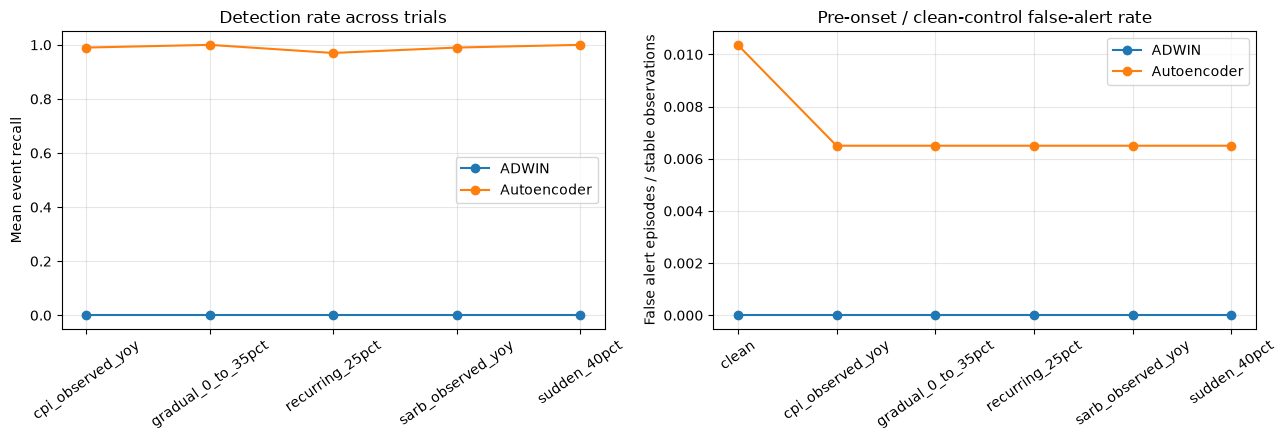

Saved to: C:\Users\yntsa\OneDrive\Documents\School\Research Data\AutoEncodesVAdwin\outputs\research_playbook
Held-out adaptation summary (post-onset labels used for retraining):


,scenario,trials,evaluation_n_mean,baseline_auc_mean,adapted_auc_mean,auc_change_mean,auc_change_sd,baseline_logloss_mean,adapted_logloss_mean,logloss_change_mean
0,cpi_observed_yoy,1,67.0,0.6947,0.6766,-0.0181,NaN,0.5753,0.6854,0.1101
1,gradual_0_to_35pct,1,67.0,0.6862,0.6957,0.0096,NaN,0.5804,0.6261,0.0457
2,recurring_25pct,1,67.0,0.7000,0.6830,-0.0170,NaN,0.5767,0.6424,0.0658
3,sarb_observed_yoy,1,67.0,0.7032,0.6809,-0.0223,NaN,0.5683,0.6828,0.1145
4,sudden_40pct,1,67.0,0.6851,0.6809,-0.0043,NaN,0.5919,0.6828,0.0909


Files: macro_calibration.csv, scenario_definitions.csv, trial_metrics.csv, adaptation_holdout_metrics.csv, primary_results_summary.csv, sensitivity_summary.csv, hypothesis_tests.csv, research_question_answers.csv, before_after_injection_summary.csv, adaptation_summary.csv, resource_summary.csv, detector_results.png


In [32]:
primary = trial_results[
    ((trial_results.detector == "Autoencoder") & (trial_results.setting == "3-sigma")) |
    ((trial_results.detector == "ADWIN") & (trial_results.setting == "family-delta-0.05"))
].copy()
summary = primary.groupby(["scenario", "detector"], as_index=False).agg(
    trials=("trial", "count"), event_recall_mean=("event_recall", "mean"),
    event_recall_sd=("event_recall", "std"), delay_mean=("delay", "mean"),
    delay_sd=("delay", "std"), false_alert_rate_mean=("false_alert_rate", "mean"),
    event_precision_mean=("event_precision", "mean"),
    false_discovery_rate_mean=("false_discovery_rate", "mean"),
    auc_operational_mean=("auc_operational", "mean"),
    auc_change_mean=("auc_change_vs_reference", "mean"), runtime_seconds_mean=("runtime_seconds", "mean"))
summary.to_csv(OUTPUT_DIR / "primary_results_summary.csv", index=False)
display(summary.round(4))

sensitivity = trial_results.groupby(["scenario", "detector", "setting"], as_index=False).agg(
    trials=("trial", "count"), event_recall_mean=("event_recall", "mean"),
    delay_mean=("delay", "mean"), false_alert_rate_mean=("false_alert_rate", "mean"),
    event_precision_mean=("event_precision", "mean"))
sensitivity.to_csv(OUTPUT_DIR / "sensitivity_summary.csv", index=False)
display(sensitivity.round(4))

# Paired tests quantify variability across autoencoder initializations on this fixed stream.
def paired_wilcoxon_pvalue(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    valid = np.isfinite(left) & np.isfinite(right)
    differences = left[valid] - right[valid]
    if len(differences) < 2:
        return np.nan, int(len(differences))
    if np.allclose(differences, 0):
        return 1.0, int(len(differences))
    return float(wilcoxon(left[valid], right[valid], alternative="two-sided").pvalue), int(len(differences))

def holm_adjust(p_values):
    adjusted = np.full(len(p_values), np.nan, dtype=float)
    valid = np.flatnonzero(np.isfinite(p_values))
    if not len(valid):
        return adjusted
    order = valid[np.argsort(np.asarray(p_values)[valid])]
    running_max = 0.0
    count = len(order)
    for rank, index in enumerate(order):
        running_max = max(running_max, (count - rank) * float(p_values[index]))
        adjusted[index] = min(1.0, running_max)
    return adjusted

primary_trials = trial_results[
    ((trial_results.detector == "Autoencoder") & (trial_results.setting == "3-sigma")) |
    ((trial_results.detector == "ADWIN") & (trial_results.setting == "family-delta-0.05"))
]
stat_rows = []
for scenario in SCENARIOS:
    ae_rows = primary_trials[(primary_trials.scenario == scenario) & (primary_trials.detector == "Autoencoder")]
    adwin_rows = primary_trials[(primary_trials.scenario == scenario) & (primary_trials.detector == "ADWIN")]
    paired = ae_rows.merge(adwin_rows, on=["trial", "scenario"], suffixes=("_ae", "_adwin"))
    ae_detected = paired["event_recall_ae"].fillna(0).to_numpy(dtype=int)
    adwin_detected = paired["event_recall_adwin"].fillna(0).to_numpy(dtype=int)
    ae_only = int(np.sum((ae_detected == 1) & (adwin_detected == 0)))
    adwin_only = int(np.sum((ae_detected == 0) & (adwin_detected == 1)))
    discordant = ae_only + adwin_only
    recall_p = float(binomtest(min(ae_only, adwin_only), discordant, p=0.5).pvalue) if discordant else 1.0
    stat_rows.append({"scenario": scenario, "metric": "event_recall", "test": "exact paired binomial (discordant initializations)",
                      "n_comparable_initializations": len(paired), "autoencoder_only_wins": ae_only,
                      "adwin_only_wins": adwin_only, "p_value_raw": recall_p})
    for metric, column in [("delay", "delay"), ("event_precision", "event_precision"),
                           ("event_fdr", "false_discovery_rate"), ("false_alert_episodes", "false_alert_events")]:
        p_value, n_pairs = paired_wilcoxon_pvalue(paired[f"{column}_ae"], paired[f"{column}_adwin"])
        stat_rows.append({"scenario": scenario, "metric": metric, "test": "paired Wilcoxon signed-rank",
                          "n_comparable_initializations": n_pairs, "autoencoder_only_wins": np.nan,
                          "adwin_only_wins": np.nan, "p_value_raw": p_value})
statistical_tests = pd.DataFrame(stat_rows)
statistical_tests["p_value_holm_within_metric"] = np.nan
for metric, indices in statistical_tests.groupby("metric").groups.items():
    statistical_tests.loc[indices, "p_value_holm_within_metric"] = holm_adjust(
        statistical_tests.loc[indices, "p_value_raw"].to_numpy(dtype=float))
statistical_tests["scope"] = "fixed records/order; repeated AE initializations only; not independent datasets"
statistical_tests.to_csv(OUTPUT_DIR / "hypothesis_tests.csv", index=False)
print("Conditional paired tests (interpret only as initialization sensitivity on this fixed stream):")
display(statistical_tests.round(4))

# A compact, explicit mapping from observed summaries to the proposal's questions.
answers = []
for rq, focus in [("RQ1", "Detection of known synthetic shifts"),
                  ("RQ2", "Detection delay and false-alert behaviour"),
                  ("RQ3", "Label-blind warning versus retrospective predictive performance")]:
    subset = summary[summary.scenario != "clean"]
    recall = subset.groupby("detector").event_recall_mean.mean().to_dict()
    delay = subset.groupby("detector").delay_mean.mean().to_dict()
    far = subset.groupby("detector").false_alert_rate_mean.mean().to_dict()
    if rq == "RQ1":
        measured = f"Mean event recall across injected scenarios: {recall}. Interpret alongside missed detections and scenario-specific values above."
    elif rq == "RQ2":
        measured = f"Mean delay (misses excluded by NaN averaging): {delay}; mean pre-onset false-alert rate: {far}. Clean-control rates are in the table."
    else:
        paired = trial_results[(trial_results.detector == "Autoencoder") & (trial_results.setting == "3-sigma")]
        paired = paired[paired.scenario != "clean"]
        auc_changes = paired.groupby("scenario").auc_post_injection_delta_vs_same_records.mean().to_dict()
        loss_changes = paired.groupby("scenario").logloss_post_injection_delta_vs_same_records.mean().to_dict()
        mean_auc_change = float(paired.auc_post_injection_delta_vs_same_records.mean())
        mean_loss_change = float(paired.logloss_post_injection_delta_vs_same_records.mean())
        pattern = ("The average paired comparison shows no AUC decline or log-loss worsening from injection."
                   if mean_auc_change >= 0 and mean_loss_change <= 0
                   else "The average paired comparison suggests possible degradation; inspect scenario variation and trial uncertainty.")
        measured = f"AUC change after injection vs the same records unmodified: {auc_changes}; log-loss change: {loss_changes}. {pattern} Labels are used retrospectively only; this cannot establish real label-delay forecasting or real P(y|X) drift."
    answers.append({"research_question": rq, "focus": focus, "measured_summary": measured})
answer_table = pd.DataFrame(answers)
display(answer_table)
answer_table.to_csv(OUTPUT_DIR / "research_question_answers.csv", index=False)

paired_summary = trial_results[(trial_results.detector == "Autoencoder") &
                                 (trial_results.setting == "3-sigma")].groupby("scenario", as_index=False).agg(
    trials=("trial", "count"), pre_onset_auc_mean=("auc_pre_onset", "mean"),
    pre_onset_logloss_mean=("logloss_pre_onset", "mean"),
    post_unmodified_auc_mean=("auc_post_unmodified_counterfactual", "mean"),
    post_injected_auc_mean=("auc_post_injected", "mean"),
    auc_injection_delta_mean=("auc_post_injection_delta_vs_same_records", "mean"),
    auc_injection_delta_sd=("auc_post_injection_delta_vs_same_records", "std"),
    post_unmodified_logloss_mean=("logloss_post_unmodified_counterfactual", "mean"),
    post_injected_logloss_mean=("logloss_post_injected", "mean"),
    logloss_injection_delta_mean=("logloss_post_injection_delta_vs_same_records", "mean"),
    logloss_injection_delta_sd=("logloss_post_injection_delta_vs_same_records", "std"))
paired_summary.to_csv(OUTPUT_DIR / "before_after_injection_summary.csv", index=False)
print("Paired classifier performance: pre-onset and post-injection vs the same records without injection")
display(paired_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for detector, group in summary.groupby("detector"):
    axes[0].plot(group.scenario, group.event_recall_mean, marker="o", label=detector)
    axes[1].plot(group.scenario, group.false_alert_rate_mean, marker="o", label=detector)
axes[0].set_title("Detection rate across trials")
axes[0].set_ylabel("Mean event recall")
axes[0].set_ylim(-0.05, 1.05)
axes[1].set_title("Pre-onset / clean-control false-alert rate")
axes[1].set_ylabel("False alert episodes / stable observations")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "detector_results.png", dpi=180, bbox_inches="tight")
plt.show()

print("Saved to:", OUTPUT_DIR)
recovery_summary = recovery_results.groupby("scenario", as_index=False).agg(
    trials=("trial", "count"), evaluation_n_mean=("evaluation_n", "mean"),
    baseline_auc_mean=("baseline_auc", "mean"), adapted_auc_mean=("adapted_auc", "mean"),
    auc_change_mean=("auc_change", "mean"), auc_change_sd=("auc_change", "std"),
    baseline_logloss_mean=("baseline_logloss", "mean"), adapted_logloss_mean=("adapted_logloss", "mean"))
recovery_summary["logloss_change_mean"] = recovery_summary["adapted_logloss_mean"] - recovery_summary["baseline_logloss_mean"]
recovery_summary.to_csv(OUTPUT_DIR / "adaptation_summary.csv", index=False)
print("Held-out adaptation summary (post-onset labels used for retraining):")
display(recovery_summary.round(4))

print("Files: macro_calibration.csv, scenario_definitions.csv, trial_metrics.csv, adaptation_holdout_metrics.csv, primary_results_summary.csv, sensitivity_summary.csv, hypothesis_tests.csv, research_question_answers.csv, before_after_injection_summary.csv, adaptation_summary.csv, resource_summary.csv, detector_results.png")

## 8. Secondary sensitivity: randomized pseudo-time stream

German Credit has no timestamps, so its records cannot be placed into an observed chronological sequence. To examine how record ordering affects streaming detectors, this secondary analysis keeps the proposal's first-700 reference and final-300 operational membership fixed, then applies 100 seeded permutations to the operational records. Each permutation is an artificial pseudo-time ordering, not reconstructed history or a real chronology.

The preprocessing, autoencoder, and calibration threshold are fitted once on the same reference training/calibration split. For each permutation, every detector receives the same pseudo-ordered records and the same scenario transformations, with onset at observation 100. The autoencoder's 3-sigma threshold and ADWIN family-wise delta 0.05 are used. These results measure sensitivity to sequence ordering for this fixed set of records and fitted models; they do not constitute 100 independent samples or population-level confidence intervals. The file-order results above remain the primary proposal-aligned analysis.

The code below exports `pseudo_time_trial_metrics.csv` and `pseudo_time_summary.csv`. Compare the results with the fixed-order primary results, but do not call either sequence chronological.


In [33]:
pseudo_time_rows = []

# Fit one detector pair on the same proposal-defined first-700 reference rows.
reference_idx = np.arange(REFERENCE_N)
train_idx = reference_idx[:560]
calibration_idx = reference_idx[560:]
raw_train = credit.iloc[train_idx].drop(columns=TARGET).copy()
raw_cal = credit.iloc[calibration_idx].drop(columns=TARGET).copy()
raw_operational = credit.iloc[REFERENCE_N:REFERENCE_N + STREAM_N].drop(columns=TARGET).copy().reset_index(drop=True)
transformer_pseudo = ColumnTransformer([
    ("numeric", RobustScaler(), NUMERIC),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
], remainder="drop")
x_train_pseudo = np.asarray(transformer_pseudo.fit_transform(raw_train), dtype=np.float32)
x_cal_pseudo = np.asarray(transformer_pseudo.transform(raw_cal), dtype=np.float32)
ae_pseudo = fit_ae(x_train_pseudo, SEED + 10000)
calibration_errors_pseudo = reconstruction_errors(ae_pseudo, x_cal_pseudo)
threshold_pseudo = float(calibration_errors_pseudo.mean() + 3 * calibration_errors_pseudo.std(ddof=0))

for order_seed in range(N_TRIALS):
    rng = np.random.default_rng(SEED + 20000 + order_seed)
    permutation = rng.permutation(len(raw_operational))
    raw_pseudo_stream = raw_operational.iloc[permutation].reset_index(drop=True)
    y_pseudo_stream = (credit.iloc[REFERENCE_N:REFERENCE_N + STREAM_N][TARGET].to_numpy()[permutation] == "good").astype(int)

    for scenario in SCENARIOS:
        shifted_raw = make_scenario(raw_pseudo_stream, scenario)
        x_pseudo_stream = np.asarray(transformer_pseudo.transform(shifted_raw), dtype=np.float32)
        onset = None if scenario == "clean" else DRIFT_ONSET

        ae_hits = np.flatnonzero(reconstruction_errors(ae_pseudo, x_pseudo_stream) > threshold_pseudo)
        ae_result = score_alerts(ae_hits, onset, len(x_pseudo_stream))
        pseudo_time_rows.append({"order_seed": order_seed, "scenario": scenario, "detector": "Autoencoder",
                                 "setting": "3-sigma", **ae_result})

        detectors = [drift.ADWIN(delta=0.05 / x_pseudo_stream.shape[1])
                     for _ in range(x_pseudo_stream.shape[1])]
        adwin_hits = []
        for row_idx, row in enumerate(x_pseudo_stream):
            flagged = False
            for detector, value in zip(detectors, row):
                detector.update(float(value))
                flagged = flagged or detector.drift_detected
            if flagged:
                adwin_hits.append(row_idx)
        adwin_result = score_alerts(adwin_hits, onset, len(x_pseudo_stream))
        pseudo_time_rows.append({"order_seed": order_seed, "scenario": scenario, "detector": "ADWIN",
                                 "setting": "family-delta-0.05", **adwin_result})

pseudo_time_results = pd.DataFrame(pseudo_time_rows)
pseudo_time_summary = pseudo_time_results.groupby(["scenario", "detector"], as_index=False).agg(
    pseudo_time_orders=("order_seed", "nunique"),
    event_recall_mean=("event_recall", "mean"), event_recall_sd=("event_recall", "std"),
    delay_mean=("delay", "mean"), delay_sd=("delay", "std"),
    false_alert_rate_mean=("false_alert_rate", "mean"),
    false_discovery_rate_mean=("false_discovery_rate", "mean"),
    event_precision_mean=("event_precision", "mean"))
pseudo_time_results.to_csv(OUTPUT_DIR / "pseudo_time_trial_metrics.csv", index=False)
pseudo_time_summary.to_csv(OUTPUT_DIR / "pseudo_time_summary.csv", index=False)
print("Seeded pseudo-time permutations:", N_TRIALS)
print("Each permutation shuffles only the fixed final-300 operational records; timestamps remain synthetic.")
display(pseudo_time_summary.round(4))


Seeded pseudo-time permutations: 100
Each permutation shuffles only the fixed final-300 operational records; timestamps remain synthetic.


,scenario,detector,pseudo_time_orders,event_recall_mean,event_recall_sd,delay_mean,delay_sd,false_alert_rate_mean,false_discovery_rate_mean,event_precision_mean
0,clean,ADWIN,100,NaN,NaN,NaN,NaN,0.0000,NaN,NaN
1,clean,Autoencoder,100,NaN,NaN,NaN,NaN,0.0062,1.0000,0.0000
2,cpi_observed_yoy,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN
3,cpi_observed_yoy,Autoencoder,100,0.91,0.2876,83.3956,54.2824,0.0064,0.3400,0.6600
4,gradual_0_to_35pct,ADWIN,100,0.01,0.1000,187.0000,NaN,0.0000,0.0000,1.0000
5,gradual_0_to_35pct,Autoencoder,100,0.99,0.1000,62.7677,43.4215,0.0064,0.3067,0.6933
6,recurring_25pct,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN
7,recurring_25pct,Autoencoder,100,0.94,0.2387,70.3298,49.4310,0.0064,0.3283,0.6717
8,sarb_observed_yoy,ADWIN,100,0.00,0.0000,NaN,NaN,0.0000,NaN,NaN
9,sarb_observed_yoy,Autoencoder,100,1.00,0.0000,57.8700,45.7109,0.0064,0.3033,0.6967


## 9. Exploratory dated macroeconomic stream

This separate analysis uses the actual monthly dates shared by the SARB total-loans-and-advances year-over-year series and the item-weighted Stats SA CPI year-over-year series. Their overlap contains 211 monthly observations from January 2009 through July 2026. It runs the detectors directly on the two standardized macro indicators in date order; it does not attach macro dates to German Credit records or treat macro alerts as borrower-level credit drift.

The earliest 60% of months train the autoencoder and fit the scaler, the next 20% calibrate the autoencoder's 3-sigma threshold, and the final 20% are the held-out alert-reporting period. ADWIN is initialized on the full dated series in order, with alerts reported only in that held-out period. The macro timeline has no independently labeled drift events, so this is descriptive monitoring only: alert dates and counts are not recall, false-alarm rates, or evidence that a specific economic event caused an alert.


Dated macro coverage: 2009-01 to 2026-07 months: 211
Held-out alert period: 2023-01 to 2026-07


,detector,training_months,calibration_months,evaluation_months,evaluation_start,evaluation_end,alert_months,first_alert_month,ae_threshold
0,Autoencoder,126,42,43,2023-01,2026-07,1,2026-02,0.122958
1,ADWIN,126,42,43,2023-01,2026-07,1,2024-12,NaN


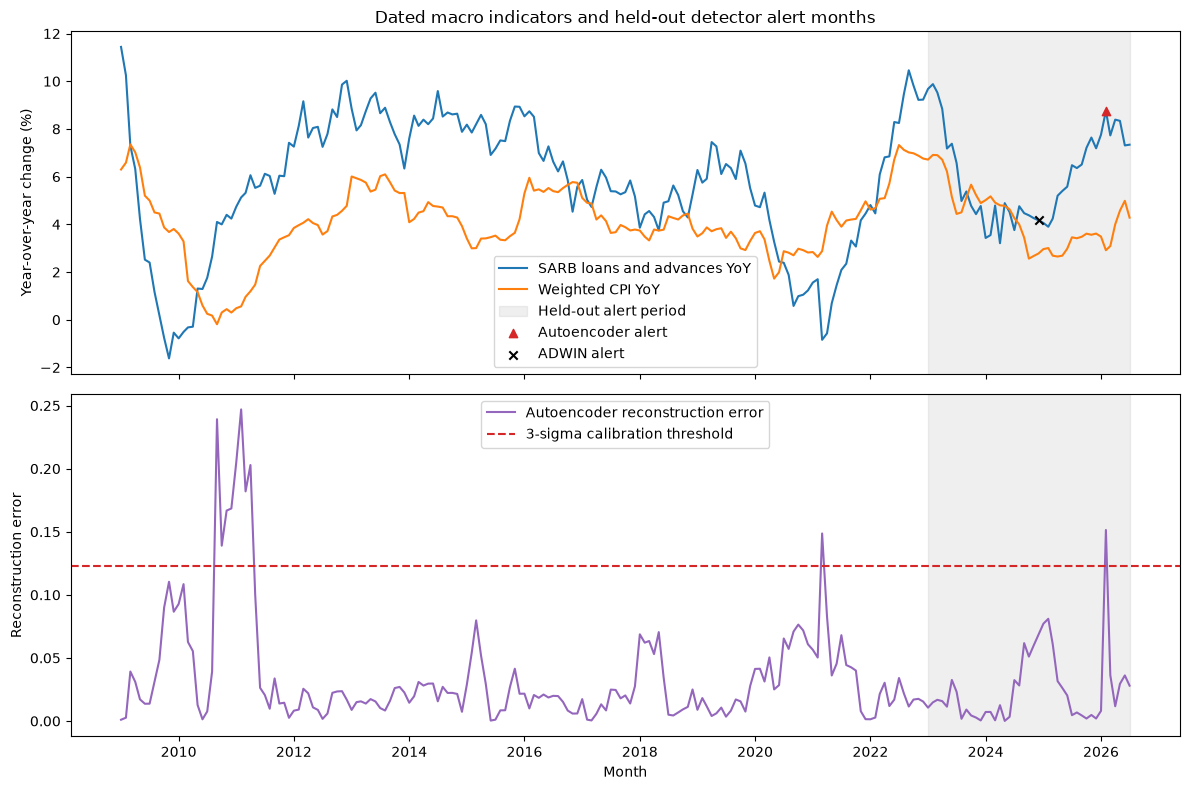

In [34]:
cpi_yoy_series = (cpi_index / cpi_index.shift(12) - 1.0) * 100.0
cpi_monthly = pd.DataFrame({
    "date": pd.to_datetime([f"{month[1:5]}-{month[5:7]}-01" for month in month_cols]),
    "cpi_yoy_pct": cpi_yoy_series.to_numpy(),
})
macro_timeline = (sarb[["date", "loans_advances_yoy_pct"]]
                  .merge(cpi_monthly, on="date", how="inner")
                  .dropna()
                  .sort_values("date")
                  .reset_index(drop=True))
macro_month_numbers = macro_timeline["date"].dt.to_period("M").astype("int64")
if macro_month_numbers.diff().dropna().ne(1).any():
    raise ValueError("The overlapping macro series must have consecutive monthly dates.")

MACRO_FEATURES = ["loans_advances_yoy_pct", "cpi_yoy_pct"]
macro_values = macro_timeline[MACRO_FEATURES].to_numpy(dtype=np.float32)
macro_train_end = int(len(macro_timeline) * 0.60)
macro_calibration_end = int(len(macro_timeline) * 0.80)
if macro_train_end < 2 or macro_calibration_end <= macro_train_end or macro_calibration_end >= len(macro_timeline):
    raise ValueError("Insufficient overlapping monthly macro observations for the chronological split.")

macro_scaler = RobustScaler()
macro_x_train = macro_scaler.fit_transform(macro_values[:macro_train_end]).astype(np.float32)
macro_x_all = macro_scaler.transform(macro_values).astype(np.float32)
torch.set_num_threads(1)
macro_ae = fit_ae(macro_x_train, SEED)
macro_reconstruction_error = reconstruction_errors(macro_ae, macro_x_all)
macro_calibration_errors = macro_reconstruction_error[macro_train_end:macro_calibration_end]
macro_ae_threshold = float(macro_calibration_errors.mean() + 3 * macro_calibration_errors.std(ddof=1))
macro_evaluation_start = macro_calibration_end
macro_ae_alert = ((np.arange(len(macro_timeline)) >= macro_evaluation_start) &
                   (macro_reconstruction_error > macro_ae_threshold))

macro_adwin_detectors = [drift.ADWIN(delta=0.05 / len(MACRO_FEATURES)) for _ in MACRO_FEATURES]
macro_adwin_alert = np.zeros(len(macro_timeline), dtype=bool)
for month_idx, row in enumerate(macro_x_all):
    flagged = False
    for detector, value in zip(macro_adwin_detectors, row):
        detector.update(float(value))
        flagged = flagged or detector.drift_detected
    macro_adwin_alert[month_idx] = month_idx >= macro_evaluation_start and flagged

macro_timed_monthly = macro_timeline.copy()
macro_timed_monthly["reconstruction_error"] = macro_reconstruction_error
macro_timed_monthly["ae_alert_in_evaluation"] = macro_ae_alert
macro_timed_monthly["adwin_alert_in_evaluation"] = macro_adwin_alert
macro_timed_monthly["evaluation_period"] = np.arange(len(macro_timeline)) >= macro_evaluation_start
macro_evaluation = macro_timeline.iloc[macro_evaluation_start:]
macro_alert_rows = []
macro_summary_rows = []
for detector_name, alert_mask in [("Autoencoder", macro_ae_alert), ("ADWIN", macro_adwin_alert)]:
    alert_indices = np.flatnonzero(alert_mask)
    first_alert = macro_timeline.loc[alert_indices[0], "date"].strftime("%Y-%m") if len(alert_indices) else None
    macro_summary_rows.append({
        "detector": detector_name,
        "training_months": macro_train_end,
        "calibration_months": macro_calibration_end - macro_train_end,
        "evaluation_months": len(macro_timeline) - macro_evaluation_start,
        "evaluation_start": macro_evaluation.iloc[0]["date"].strftime("%Y-%m"),
        "evaluation_end": macro_evaluation.iloc[-1]["date"].strftime("%Y-%m"),
        "alert_months": len(alert_indices),
        "first_alert_month": first_alert,
        "ae_threshold": macro_ae_threshold if detector_name == "Autoencoder" else np.nan,
    })
    for alert_idx in alert_indices:
        macro_alert_rows.append({
            "detector": detector_name,
            "date": macro_timeline.loc[alert_idx, "date"],
            "loans_advances_yoy_pct": macro_timeline.loc[alert_idx, "loans_advances_yoy_pct"],
            "cpi_yoy_pct": macro_timeline.loc[alert_idx, "cpi_yoy_pct"],
            "reconstruction_error": macro_reconstruction_error[alert_idx],
        })

macro_timed_summary = pd.DataFrame(macro_summary_rows)
macro_timed_alerts = pd.DataFrame(macro_alert_rows, columns=[
    "detector", "date", "loans_advances_yoy_pct", "cpi_yoy_pct", "reconstruction_error"
])
macro_timed_monthly.to_csv(OUTPUT_DIR / "macro_timed_monthly.csv", index=False)
macro_timed_alerts.to_csv(OUTPUT_DIR / "macro_timed_alerts.csv", index=False)
macro_timed_summary.to_csv(OUTPUT_DIR / "macro_timed_summary.csv", index=False)
print("Dated macro coverage:", macro_timeline.date.iloc[0].strftime("%Y-%m"), "to",
      macro_timeline.date.iloc[-1].strftime("%Y-%m"), "months:", len(macro_timeline))
print("Held-out alert period:", macro_evaluation.date.iloc[0].strftime("%Y-%m"), "to",
      macro_evaluation.date.iloc[-1].strftime("%Y-%m"))
display(macro_timed_summary)

fig, (ax_series, ax_error) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax_series.plot(macro_timeline["date"], macro_timeline["loans_advances_yoy_pct"],
               label="SARB loans and advances YoY", color="tab:blue")
ax_series.plot(macro_timeline["date"], macro_timeline["cpi_yoy_pct"],
               label="Weighted CPI YoY", color="tab:orange")
evaluation_date = macro_timeline.loc[macro_evaluation_start, "date"]
ax_series.axvspan(evaluation_date, macro_timeline["date"].iloc[-1], color="grey", alpha=0.12,
                  label="Held-out alert period")
for detector_name, alert_mask, marker, color in [
    ("Autoencoder alert", macro_ae_alert, "^", "tab:red"),
    ("ADWIN alert", macro_adwin_alert, "x", "black"),
]:
    selected = macro_timeline.loc[alert_mask]
    if not selected.empty:
        ax_series.scatter(selected["date"], selected["loans_advances_yoy_pct"],
                          marker=marker, color=color, label=detector_name, zorder=3)
ax_series.set_ylabel("Year-over-year change (%)")
ax_series.legend(loc="best")
ax_series.set_title("Dated macro indicators and held-out detector alert months")
ax_error.plot(macro_timeline["date"], macro_reconstruction_error,
              label="Autoencoder reconstruction error", color="tab:purple")
ax_error.axhline(macro_ae_threshold, linestyle="--", color="tab:red", label="3-sigma calibration threshold")
ax_error.axvspan(evaluation_date, macro_timeline["date"].iloc[-1], color="grey", alpha=0.12)
ax_error.set_ylabel("Reconstruction error")
ax_error.set_xlabel("Month")
ax_error.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "macro_timed_detection.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Findings, interpretation, and write-up checklist

### Primary proposal-aligned file-order results

The primary analysis uses the first 700 ARFF records as the reference set and the final 300 as the operational stream, in file order. The 100 repeated runs vary autoencoder training randomness (weight initialization and minibatch order); they do not resample records. The shift begins at synthetic stream position 100. Detection delay is measured in observations after onset, not calendar time.

| Scenario | AE recall | AE mean delay (observations) | AE event FDR | ADWIN recall | ADWIN delay |
|---|---:|---:|---:|---:|---:|
| Sudden 40% | 1.00 | 17.5 | 0.295 | 0.00 | Not detected |
| Gradual 0-to-35% | 1.00 | 21.9 | 0.295 | 0.00 | Not detected |
| Recurring 25% | 0.97 | 19.7 | 0.308 | 0.00 | Not detected |
| SARB-anchored lending-growth | 0.99 | 19.0 | 0.300 | 0.00 | Not detected |
| CPI-anchored | 0.99 | 21.0 | 0.300 | 0.00 | Not detected |

On the fixed file-order stream, the autoencoder detected nearly every injected event. ADWIN at family-wise delta 0.05 did not alert. The autoencoder's pre-onset false-alert rate was 0.0065 episodes per stable observation in shifted scenarios; its clean-control rate was 0.0104 per observation, and every clean-control alert was false. Event-level FDR was approximately 0.30 for the autoencoder in shifted scenarios. ADWIN's no-alert result means its delay and event FDR are undefined; do not describe it as having a measured fast or slow delay.

Paired tests with Holm correction found training-seed-conditional differences in event recall and false-alert episode counts (adjusted p < 0.001). They compare outcomes over autoencoder weight initializations and minibatch orders on one fixed record sequence. These are not tests across independent data samples. Since ADWIN made no primary-setting detections, comparative latency and detected-event precision/FDR tests are not estimable; the proposal's full null/alternative hypothesis about both latency and precision is therefore not fully established.

### Secondary randomized pseudo-time sensitivity

German Credit has no timestamps. The secondary analysis randomly permutes only the fixed final-300 operational records using 100 reproducible seeds, then applies the same shift-onset position and scenarios. These are synthetic pseudo-time sequences, not reconstructed or observed chronology. The autoencoder and ADWIN are held fixed across these permutations, so variation here reflects record-order sensitivity for this one dataset and fitted detector pair.

| Scenario | AE recall | AE mean delay (observations) | ADWIN recall | ADWIN mean delay |
|---|---:|---:|---:|---:|
| Clean control | N/A | N/A | N/A | N/A |
| Sudden 40% | 1.00 | 41.9 | 0.16 | 121.0 |
| Gradual 0-to-35% | 0.99 | 62.8 | 0.01 | 187.0 |
| Recurring 25% | 0.94 | 70.3 | 0.00 | Not detected |
| SARB-anchored lending-growth | 1.00 | 57.9 | 0.00 | Not detected |
| CPI-anchored | 0.91 | 83.4 | 0.00 | Not detected |

The permutation replay changed some results: AE delays were longer than in the file-order analysis, while ADWIN detected some sudden-shift streams and one gradual-shift stream. This demonstrates that detection depends on which records arrive before and after onset. It does not show that pseudo-time is more realistic or that either order represents real borrower history. The fixed file-order analysis remains primary; pseudo-time is a sensitivity check. Its 100 orders are not 100 independent datasets or population-level uncertainty estimates.

### Threshold sensitivity and resource measurements

Across injected scenarios in the primary file-order analysis, mean AE recall was 1.00 at 2 sigma, 0.99 at 3 sigma, and 0.812 at 4 sigma. Mean delay among detections was approximately 14.7, 19.8, and 28.7 observations. Clean-control false-alert rates were 0.0260, 0.0104, and 0.0029 episodes per observation, respectively. ADWIN's mean recall was 0 at family-wise deltas 0.01 and 0.05, and 0.20 at 0.10; at 0.10 it detected only the sudden-shift scenario. More sensitive AE thresholds increased detection and false alerts.

Mean stream-scoring runtime per 300-record stream was about 0.00054 seconds for AE and 0.0086 seconds for ADWIN's per-feature updates. Autoencoder training averaged about 0.23 seconds per training-seed run and is excluded from inference time. Sampled process RSS during repeated scoring was about 533.7 MB peak, with an incremental sampled rise around 0.19 MB for AE scoring and less than 0.01 MB for ADWIN. RSS includes the interpreter, dataset, and fitted model; this coarse local measurement is not detector-only memory use or a production estimate.

### Predictive performance and simulated adaptation

For the fixed file-order stream, paired injected-minus-unmodified AUC differences were +0.0019 to +0.0091; paired log-loss differences ranged from -0.0081 to +0.0050. These are descriptive effects on the same fixed records and classifier, not general evidence of improvement. Labels were unchanged by design, so the feature perturbations do not test natural concept drift in `P(y|X)`.

The separate adaptation exercise is now run once per scenario because the fixed records and XGBoost settings make repeating it redundant. It retrains with labels from the first two-thirds of post-onset records and evaluates on the final third (67 records). Results differ by scenario: adaptation AUC changes ranged from -0.0223 to +0.0096, while log-loss worsened in all five scenarios (+0.0457 to +0.1145). This small retrospective-label simulation does not demonstrate general recovery or deployment readiness.

### Dated macroeconomic stream (exploratory)

The separate macro-only replay uses the 211 actual overlapping monthly observations from January 2009 through July 2026. Its held-out evaluation covers January 2023 through July 2026. The autoencoder flagged February 2026 and ADWIN flagged December 2024. These alert dates describe the two macro indicators only. There are no labeled macro drift events, and these data are not linked to German Credit borrowers, so the replay does not provide recall, false-alarm rates, credit-model performance, or evidence of borrower-level chronology.

### Final research-project drafting checklist

- [ ] Use the first-700/next-300 file-order analysis as the primary proposal-aligned experiment.
- [ ] Report the separate randomized pseudo-time analysis as a sensitivity check, explicitly stating the order is artificial and not chronological.
- [ ] State that German Credit has no timestamps; row order and permutations are not borrower history.
- [ ] Explain that the 100 primary repetitions vary autoencoder training randomness; the 100 pseudo-time runs vary ordering. Neither is 100 independent datasets.
- [ ] Cite `primary_results_summary.csv`, `pseudo_time_summary.csv`, `hypothesis_tests.csv`, `resource_summary.csv`, `macro_calibration.csv`, `before_after_injection_summary.csv`, and the single-run-per-scenario `adaptation_summary.csv`.
- [ ] Define event recall, observation-based delay, false-alert episode rate, and event-level FDR separately. Do not call the episode rate FDR.
- [ ] Report that ADWIN produced no alerts in the primary fixed-order comparison; its delay and event FDR are therefore not estimable at that setting.
- [ ] Describe hypothesis tests as conditional on fixed records and repeated AE training seeds; do not generalize their p-values to independent populations.
- [ ] Separate feature-distribution alerts from predictive performance. Labels were held unchanged, so natural `P(y|X)` drift was not tested.
- [ ] Describe adaptation as one held-out, retrospective-label simulation per scenario; do not claim successful recovery.
- [ ] Distinguish the primary analysis, which does not simulate label arrival, from the supplementary synthetic 0/25/50-observation label-delay experiment; neither reproduces real borrower-outcome maturation.
- [ ] Report SARB total loans and advances YoY growth (7.34%) and weighted CPI YoY (4.2823%) for 2026-07 as scenario calibration, not borrower-linked measures.
- [ ] Describe the dated macro-only alert replay as exploratory and report alert dates, not accuracy metrics; do not associate macro timestamps with credit records.
- [ ] Cite `macro_timed_summary.csv`, `macro_timed_alerts.csv`, `macro_timed_monthly.csv`, and `macro_timed_detection.png` for the dated macro-only exploration.
- [ ] Compare the findings with the literature and proposal, and explain design changes and limits rather than claiming every proposed assumption was validated.


## Answers to the Research Questions

These answers refer first to the primary fixed-file-order analysis and then, where relevant, the separate randomized pseudo-time sensitivity. The dated macro-only replay is a separate exploratory use of actual macro timestamps; none of these analyses provides real borrower chronology.

### RQ1. How accurately do the selected unsupervised methods identify distribution shifts?

In the primary first-700/next-300 file-order analysis, AE event recall ranged from 0.97 to 1.00 across the five injected scenarios; ADWIN at family-wise delta 0.05 detected none. In the secondary pseudo-time replay, AE recall ranged from 0.91 to 1.00. ADWIN recall ranged from 0 to 0.16 and detected some sudden-shift permutations plus one gradual-shift permutation. This indicates that the tested AE was more sensitive on these synthetic scenarios, while ADWIN's results depended more on the stream ordering. The conclusion is limited to one 1,000-record German Credit benchmark and synthetic shifts; it is not a general accuracy estimate for financial datasets.

### RQ2. How do responsiveness and false-alert behavior compare?

On the fixed file-order stream, AE conditional mean delays were 17.5-21.9 observations; ADWIN raised no primary-setting alerts, so its delay cannot be estimated. In pseudo-time permutations, AE delays increased to 41.9-83.4 observations by scenario. ADWIN detected only 16% of sudden-shift permutations (mean delay 121 observations) and 1% of gradual-shift permutations (187 observations); no detections in the other scenarios mean no delay estimate there. ADWIN had no false alerts at the primary setting. AE had a clean-control false-alert rate of 0.0104 episodes per observation and an event-level FDR around 0.30 across injected file-order scenarios. These results show a sensitivity/false-alert trade-off in the tested setup, not operational performance under real verification latency.

The conditional paired tests show differences in event recall and false-alert episodes over training-seed variation or pseudo-order variation, respectively; they do not support population-wide inference. Because ADWIN had no primary fixed-order detections, the proposed comparative latency and precision hypothesis is not fully testable from that primary comparison.

### RQ3. Can feature-only monitoring provide early warning of predictive instability without immediate labels?

The detectors use features without labels, and AE generated alerts for these injected feature changes. This demonstrates label-free feature monitoring in a controlled simulation, not reliable prediction of future model instability. Paired classifier score changes were small and scenario-dependent. Because the injection retained the original labels and the benchmark has no temporal outcomes, the study does not establish natural `P(y|X)` drift, a consistent alert-to-performance relationship, or warning lead time before real borrower outcomes arrive.

### Overall answer

The central detector comparison follows the proposal's fixed first-700/next-300 file-order split and implements the main synthetic stress scenarios. AE detected most injected changes; ADWIN made no alerts in the primary setting. Supplementary tests add repeated events under a shared calibrated alert budget and simulate ADWIN on prediction loss under 0/25/50-observation label delay. These additions move closer to the proposal's precision and latency questions, but the operational clean-stream false-alert rate showed that calibration did not transport from the reference validation subset to the held-out operational records. The outcome shift is synthetic and its loss monitor is label-dependent. The pseudo-time replay remains artificial, and the dated macro replay concerns only aggregate indicators. No extension creates a dated South African borrower history or validates real-world model risk.

### Alignment with the research proposal

| Proposal element | Execution status | What the evidence supports |
|---|---|---|
| Compare an unsupervised autoencoder with ADWIN for feature-distribution change | **Implemented** | Both detectors receive the same encoded features in the fixed-order benchmark; results are specific to these models, settings, and synthetic scenarios. |
| Use the specified first-700 reference / final-300 stream design | **Implemented as file order** | Membership and row order are preserved, but the German Credit records have no dates; this is not an observed chronological credit stream. |
| Evaluate known sudden, gradual, recurring, and macro-calibrated shifts | **Implemented synthetically** | Detection is measured against injected onset positions. SARB/CPI values calibrate perturbations; they are not linked to individual borrowers. |
| Compare detection recall, delay, and false alerts | **Partially answerable** | Primary fixed-setting ADWIN produced no alerts, so its delay/FDR were undefined. Supplementary multi-event tests calibrate both input detectors to a shared validation budget; ADWIN detected only 1 of 300 events and AE event precision was low, with operational clean false alerts exceeding the calibration budget. |
| Examine whether feature-only alerts precede predictive instability | **Synthetic outcome shift added; real early-warning value not established** | A controlled label-mechanism shift substantially increased loss; ADWIN on delayed loss detected it after labels arrived. Input-only detector outputs were unchanged by label changes and cannot identify P(Y|X) drift without labels. |
| Use dates to create a realistic chronological credit stream | **Not possible with this dataset** | The pseudo-time sequence is artificial. The new macro-only replay preserves actual SARB/CPI dates, but its alerts concern macro indicators, not borrowers or credit risk. |
| Assess operational verification delay, generalizability, and deployment performance | **Partially simulated; real-world claims not established** | Synthetic delays of 0/25/50 observations were tested, but no realistic label-maturation process or independent credit datasets were available; resource figures are local process measurements. |

Overall, alignment is **strong for the proposal's core detector-comparison design and controlled drift scenarios**, with supplementary tests now addressing multi-event precision, a shared calibration budget, and label-delayed loss monitoring. Evidence remains **conditional and partial**: budget calibration did not transport to operational clean streams, ADWIN input monitoring detected very few repeated events, and the outcome shift was simulated. The final report should present the additions as closer tests of the hypotheses, not as validation of real-world effectiveness.

### Dated macroeconomic indicators

The separate macro-only replay preserves the actual monthly dates of the overlapping SARB and CPI series. In the January 2023-July 2026 evaluation window, the autoencoder flagged February 2026 and ADWIN flagged December 2024. These alerts concern only the macro indicators, have no independent event labels for accuracy scoring, and cannot be interpreted as credit-borrower drift.

### Final research-project drafting checklist

- [ ] Use the first-700/next-300 file-order analysis as the primary proposal-aligned experiment.
- [ ] Report the separate randomized pseudo-time analysis as a sensitivity check, explicitly stating the order is artificial and not chronological.
- [ ] State that German Credit has no timestamps; row order and permutations are not borrower history.
- [ ] Explain that the 100 primary repetitions vary autoencoder training randomness; the 100 pseudo-time runs vary ordering. Neither is 100 independent datasets.
- [ ] Cite `primary_results_summary.csv`, `pseudo_time_summary.csv`, `hypothesis_tests.csv`, `resource_summary.csv`, `macro_calibration.csv`, `before_after_injection_summary.csv`, and the single-run-per-scenario `adaptation_summary.csv`.
- [ ] Define event recall, observation-based delay, false-alert episode rate, and event-level FDR separately. Do not call the episode rate FDR.
- [ ] Report that ADWIN produced no alerts in the primary fixed-order comparison; its delay and event FDR are therefore not estimable at that setting.
- [ ] Describe hypothesis tests as conditional on fixed records and repeated AE training seeds; do not generalize their p-values to independent populations.
- [ ] Separate feature-distribution alerts from predictive performance. Labels were held unchanged, so natural `P(y|X)` drift was not tested.
- [ ] Describe adaptation as one held-out, retrospective-label simulation per scenario; do not claim successful recovery.
- [ ] Distinguish the primary no-delay analysis from supplementary synthetic 0/25/50-observation label-delay tests; do not equate simulated delays with real credit-outcome maturation.
- [ ] Report SARB total loans and advances YoY growth (7.34%) and weighted CPI YoY (4.2823%) for 2026-07 as scenario calibration, not borrower-linked measures.
- [ ] Describe the dated macro-only alert replay as exploratory and report alert dates, not accuracy metrics; do not associate macro timestamps with credit records.
- [ ] Cite `macro_timed_summary.csv`, `macro_timed_alerts.csv`, `macro_timed_monthly.csv`, and `macro_timed_detection.png` for the dated macro-only exploration.
- [ ] Use the proposal-alignment table above to distinguish implemented, partially answerable, and untested elements.
- [ ] Compare the findings with the literature and proposal, and explain design changes and limits rather than claiming every proposed assumption was validated.


## 11. Extended tests for the proposal hypothesis

This section adds repeated known input-shift events, detector threshold calibration to a shared 5% false-alert budget, bootstrap test streams, a controlled outcome-relationship shift, and ADWIN monitoring of prequential loss under 0-, 25-, and 50-observation label delays. Loss-based monitoring is explicitly label-dependent; it is not an unsupervised early-warning method. All bootstrap repetitions reuse the same finite German Credit benchmark and do not represent independent populations or borrower histories.

Threshold selection uses 70 reference calibration records for tuning and 70 separate reference records for a clean-stream validation budget. One hundred bootstrap streams from the fixed operational records form the test set. Results are conditional on this small benchmark and the resampling scheme. For the label-shift negative control, input detectors receive the same feature sequence regardless of the simulated outcomes; their alerts cannot be interpreted as detecting a change in `P(Y|X)`.

In [35]:
from run_hypothesis_extensions import run as run_hypothesis_extensions

extension_results = run_hypothesis_extensions()
display(extension_results["calibration"])
display(extension_results["multi_event"].round(4))
display(extension_results["multi_event_comparison"].round(4))
display(extension_results["outcome_shift"].round(4))

Shared stream-level false-alert budget: 0.05
Calibration set split: 70 tuning / 70 validation records
Bootstrap test streams: 100 from the fixed 300-record stream
Selected settings:
         detector     selected_setting  threshold_or_delta  clean_stream_false_alert_rate
Autoencoder-input error-quantile-0.975             0.16147                            0.0
      ADWIN-input     family-delta-0.5             0.50000                            0.0
   ADWIN-log-loss            delta-0.5             0.50000                            0.0

Repeated-event feature-shift results:
         detector  streams  events  event_recall  mean_delay  delay_sd  event_precision  event_fdr  false_alert_rate  mean_alert_episodes  clean_operational_false_alert_rate  clean_operational_stream_alert_rate
      ADWIN-input      100     300        0.0033      15.000       NaN           1.0000     0.0000            0.0000                 0.01                              0.0000                                  0

         detector     selected_setting  threshold_or_delta  clean_stream_false_alert_rate
Autoencoder-input error-quantile-0.975             0.16147                            0.0
      ADWIN-input     family-delta-0.5             0.50000                            0.0
   ADWIN-log-loss            delta-0.5             0.50000                            0.0

         detector  streams  events  event_recall  mean_delay  delay_sd  event_precision  event_fdr  false_alert_rate  mean_alert_episodes  clean_operational_false_alert_rate  clean_operational_stream_alert_rate
      ADWIN-input      100     300        0.0033      15.000       NaN           1.0000     0.0000            0.0000                 0.01                              0.0000                                  0.0
Autoencoder-input      100     300        0.5433      16.546    9.1855           0.3709     0.6291            0.0142                 4.39                              0.0137                                  1.0

                                            metric  paired_n_streams  mean_difference  bootstrap_ci_95_low  bootstrap_ci_95_high
   per-stream event recall difference (AE - ADWIN)               100           0.5400               0.4867                0.5967
per-stream event precision difference (AE - ADWIN)                 1          -0.7143              -0.7143               -0.7143

         detector  label_delay  streams  event_recall  mean_detection_delay  delay_sd  mean_delay_after_label_available  event_precision  event_fdr  mean_pre_onset_false_alert_rate  mean_auc_before  mean_auc_after_shift  mean_logloss_before  mean_logloss_after_shift  mean_flipped_outcomes  input_alert_after_label_onset  input_alert_episodes
      ADWIN-input            0      100           NaN                   NaN       NaN                               NaN              NaN        NaN                            0.000           0.7778                0.3517               0.5142                    1.2879                  160.5                           0.00                  0.00
   ADWIN-log-loss            0      100           1.0                 27.96    5.4863                             27.96            0.985      0.015                            0.000           0.7778                0.3517               0.5142                    1.2879                  160.5                         